Libraries Loaded

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt

In [2]:
councilArea = gpd.read_file("scottishBorders.geojson")
print (councilArea.head())

     LAD26CD           LAD26NM  \
0  S12000026  Scottish Borders   

                                            geometry  
0  MULTIPOLYGON (((-2.12925 55.73902, -2.12917 55...  


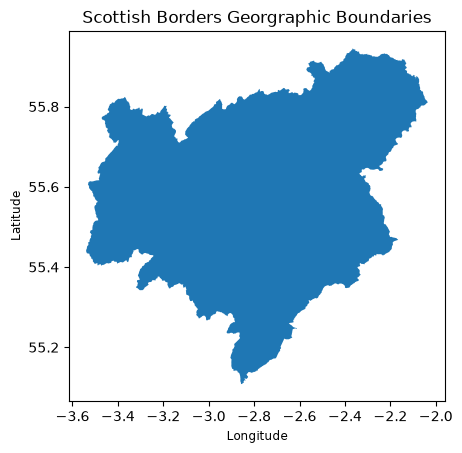

In [3]:
councilArea.plot()
plt.title("Scottish Borders Georgraphic Boundaries")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

Change the boundary area for SBC to grid reference rather than latitude and Longitude

In [5]:
gridCouncilArea = councilArea.to_crs(epsg = 27700)

Add 10km Buffer to Area to account for roads that leave council area and come back in.

In [7]:
roadNetwork = gridCouncilArea.copy()
roadNetwork ["geometry"] = gridCouncilArea.buffer(10000)

Full Road Data Loaded and Rectangular Bounds found

In [8]:
fullRoadFile = "oproad_gb.gpkg"
bounds = tuple(roadNetwork.total_bounds)

Read In Data for Bound Area

In [10]:
roadLinks = gpd.read_file(fullRoadFile, layer = "road_link", bbox = bounds)
roadNodes = gpd.read_file(fullRoadFile, layer = "road_node", bbox = bounds)

Trimmed to fit exact council area plus buffer

In [11]:
roadLinks = gpd.clip(roadLinks, roadNetwork)
roadNodes = gpd.clip(roadNodes, roadNetwork)

Image to show road network inside the boundaries

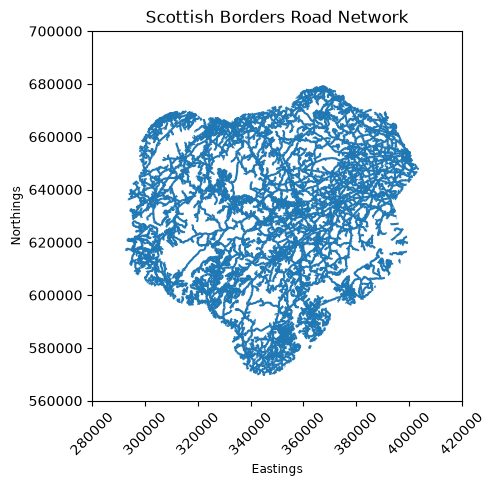

In [17]:
ax = councilArea.plot(color = "none", edgecolor = "red")
roadLinks.plot(ax = ax)
plt.xlim(280000, 420000)
plt.ylim(560000, 700000)
plt.title("Scottish Borders Road Network")
plt.xlabel("Eastings")
plt.ylabel ("Northings")
ax.tick_params(axis = "x", labelrotation = 45)
plt.show()

Road data saved for use in project

In [18]:
roadLinks.to_file("borderRoadNetwork.gpkg", layer = "road_link", driver = "GPKG")
roadNodes.to_file("borderRoadNetwork.gpkg", layer = "road_node", driver = "GPKG")

Data Aknowledgement 
Contains OS data © Crown Copyright and database rights 2026.
